# Hyperparameter sensitivity: does tuning change the evaluation?

Reviewer response. The benchmark runs every generator at its library defaults. This notebook asks one question:
**if a neural generator's hyperparameters are moved to a reasonable alternative, do its fidelity, utility and
privacy results change?** It is not a search for the best setting.

One knob moves per arm, everything else stays at the default, and every arm is at ε = 1:

| Generator | Arm | What moved |
|---|---|---|
| DP-CTGAN | default | B = 500, σ = 5 (SmartNoise defaults; ε is a stopping rule) |
| DP-CTGAN | B=250, B=100 | batch size only |
| DP-CTGAN | σ calibrated | σ solved so ε = 1 is spent over all 300 epochs (σ = 17.8 on full data, 86.6 on the 500-row audit) |
| CTGAN | default | B = 200 (synthcity default) |
| CTGAN | B=100, B=50 | batch size only |

The tuned arms were produced on gpu4-0 (Oct 2026) with the same scripts, seeds, training data, audit background, target and
attacks as the benchmark. To keep the privacy comparison on one machine, the **default privacy rows are the defaults
re-audited on gpu4-0** (DP-CTGAN `bs500`, CTGAN `bs200`), so every privacy row below ran on the same server. The
**default fidelity and utility rows are the existing benchmark results** (generated on gpu2-119-3, Aug/Sep 2026): the
defaults were not regenerated on gpu4-0, so those two comparisons cross servers.

Sources: fidelity/utility from `evaluation/results/` (default) and `evaluation/results/tuning/` (arms); privacy from
`results/tuning/` for every row (the defaults are the `bs500` / `bs200` re-audits). For reference, the original
gpu2-119-3 audits in `results/sample_size_sweep/` agree with the re-audits (see the takeaways).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from scipy.stats import ttest_ind

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "seeds.py").exists())
EVAL = REPO / "evaluation" / "results"
AUDIT = REPO / "benchmark_tapas" / "results"
FIG = AUDIT / "figures" / "supplementary"

# Same scaffolding colours and tidy() as privacy_analysis.ipynb, so the figure matches the paper's.
INK, MUTED, GRID = "#3A3A3A", "#6B6B6B", "#DDDDDD"
NEURAL = "#D55E00"      # Okabe-Ito Vermillion: the paper's tradeoff plot colours both neural generators this way
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.facecolor": "white", "font.size": 10})

def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=10, length=3)
    ax.set_axisbelow(True)

# One row per arm. tag=None is the committed default; audit_dir is where its 1000/2500 audit lives.
ARMS = [
    # method,   label,             tag,        audit_dir
    ("dpctgan", "default",         None,       AUDIT / "tuning/dp_ctgan/bs500"),
    ("dpctgan", "B=250",           "bs250",    AUDIT / "tuning/dp_ctgan/bs250"),
    ("dpctgan", "B=100",           "bs100",    AUDIT / "tuning/dp_ctgan/bs100"),
    ("dpctgan", "σ calibrated",    "sigmacal", AUDIT / "tuning/dp_ctgan/sigmacal"),
    ("ctgan",   "default",         None,       AUDIT / "tuning/ctgan/bs200"),
    ("ctgan",   "B=100",           "bs100",    AUDIT / "tuning/ctgan/bs100"),
    ("ctgan",   "B=50",            "bs50",     AUDIT / "tuning/ctgan/bs50"),
]
NAME = {"dpctgan": "DP-CTGAN", "ctgan": "CTGAN"}

# Bar charts follow the paper's bar-chart encoding: one hue per generator (Okabe-Ito Yellow darkened for DP-CTGAN,
# Vermillion for CTGAN), DP bars hatched and non-DP solid. Each generator has its own row/panel, so the two hues are
# never compared side by side. Within a generator, variants are told apart by their x-axis label and by face opacity:
# darkest is the default, lighter are the tuned arms in the order shown.
GEN_COLOR = {"dpctgan": "#A98600", "ctgan": "#D55E00"}
GEN_DP = {"dpctgan": True, "ctgan": False}
VARIANT_ALPHA = [.9, .6, .4, .25]

def variants(method):
    return [(label, tag) for m, label, tag, _ in ARMS if m == method]

def bar_style(method, i):
    return dict(facecolor=to_rgba(GEN_COLOR[method], VARIANT_ALPHA[i]), edgecolor=GEN_COLOR[method], lw=1.5,
                hatch="///" if GEN_DP[method] else None)

def seed_bars(ax, kind, method, metric):
    # One bar per variant: mean over the 5 generation seeds, ± sd, and the 5 seed values as dots.
    labels = []
    for i, (label, tag) in enumerate(variants(method)):
        v = per_run(kind, method, tag)[metric]
        ax.bar(i, v.mean(), .72, zorder=2, **bar_style(method, i))
        ax.errorbar(i, v.mean(), yerr=v.std(ddof=1), fmt="none", ecolor=INK, elinewidth=1.1, capsize=3, zorder=3)
        ax.scatter(i + np.linspace(-.18, .18, len(v)), v, s=9, color=INK, zorder=4)
        labels.append(label)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9, color="black")
    ax.set_xlim(-.6, len(labels) - .4)
    tidy(ax)
    ax.tick_params(labelcolor="black")
    ax.grid(axis="y", color=GRID, lw=.6, alpha=.5)

def per_run(kind, method, tag):
    # Per-seed fidelity or utility scores for one arm, or None if that arm has none.
    if tag is None:
        df = pd.read_csv(EVAL / f"{kind}_per_run.csv")
        return df[df.method == method]
    path = EVAL / "tuning" / f"{kind}_per_run_{method}_{tag}.csv"
    return pd.read_csv(path) if path.exists() else None

def compare(kind, metrics):
    # One table: mean ± sd over seeds per arm, and the change from that generator's default with a Welch p-value.
    rows = []
    for method, label, tag, _ in ARMS:
        arm, base = per_run(kind, method, tag), per_run(kind, method, None)
        row = {("", "generator"): NAME[method], ("", "arm"): label}
        for m in metrics:
            row[(m, "mean ± sd")] = f"{arm[m].mean():.3f} ± {arm[m].std(ddof=1):.3f}"
            if tag is None:
                row[(m, "Δ vs default (p)")] = "—"
            else:
                p = ttest_ind(arm[m], base[m], equal_var=False).pvalue
                row[(m, "Δ vs default (p)")] = f"{arm[m].mean() - base[m].mean():+.3f} ({p:.2f})"
        rows.append(row)
    out = pd.DataFrame(rows)
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    return out.set_index([("", "generator"), ("", "arm")]).rename_axis(["generator", "arm"])

## 1. Fidelity

SDMetrics scores against the training data (higher is better), 5 generation seeds per arm.
Δ is the arm's mean minus its generator's default; p is a Welch t-test over the 5 + 5 seeds.
With 7 metrics × 5 tuned arms there are 35 tests here and in section 2, so one or two p ≈ 0.05 are expected by chance.

The figure under the table has one panel per metric and one row per generator. Bars are the mean over 5 seeds, whiskers
± sd, dots the 5 seeds. DP-CTGAN is hatched (DP), CTGAN solid; the darkest bar is the default, lighter bars are the
tuned arms.

In [2]:
FIDELITY = ["KSComplement", "TVComplement", "CorrelationSimilarity", "ContingencySimilarity"]
compare("fidelity", FIDELITY)

KSComplement                    TVComplement  \
                            mean ± sd Δ vs default (p)      mean ± sd   
generator arm                                                           
DP-CTGAN  default       0.359 ± 0.085                —  0.706 ± 0.060   
          B=250         0.381 ± 0.050    +0.022 (0.63)  0.660 ± 0.062   
          B=100         0.480 ± 0.076    +0.121 (0.05)  0.646 ± 0.068   
          σ calibrated  0.439 ± 0.057    +0.080 (0.12)  0.711 ± 0.058   
CTGAN     default       0.664 ± 0.087                —  0.871 ± 0.038   
          B=100         0.716 ± 0.058    +0.052 (0.30)  0.849 ± 0.036   
          B=50          0.698 ± 0.060    +0.035 (0.49)  0.847 ± 0.030   

                                        CorrelationSimilarity  \
                       Δ vs default (p)             mean ± sd   
generator arm                                                   
DP-CTGAN  default                     —         0.889 ± 0.029   
          B=250           -0.046 (0.27)         0.878 ± 0.032   
          B=100           -0.060 (0.18)         0.871 ± 0.027   
          σ calibrated    +0.005 (0.90)         0.836 ± 0.060   
CTGAN     default                     —         0.985 ± 0.003   
          B=100           -0.023 (0.36)         0.981 ± 0.003   
          B=50            -0.025 (0.29)         0.979 ± 0.004   

                                        ContingencySimilarity                   
                       Δ vs default (p)             mean ± sd Δ vs default (p)  
generator arm                                                                   
DP-CTGAN  default                     —         0.544 ± 0.070                —  
          B=250           -0.011 (0.58)         0.471 ± 0.084    -0.073 (0.17)  
          B=100           -0.018 (0.33)         0.438 ± 0.077    -0.106 (0.05)  
          σ calibrated    -0.053 (0.13)         0.527 ± 0.076    -0.018 (0.71)  
CTGAN     default                     —         0.772 ± 0.068                —  
          B=100           -0.004 (0.07)         0.731 ± 0.061    -0.041 (0.35)  
          B=50            -0.006 (0.04)         0.721 ± 0.054    -0.050 (0.23)

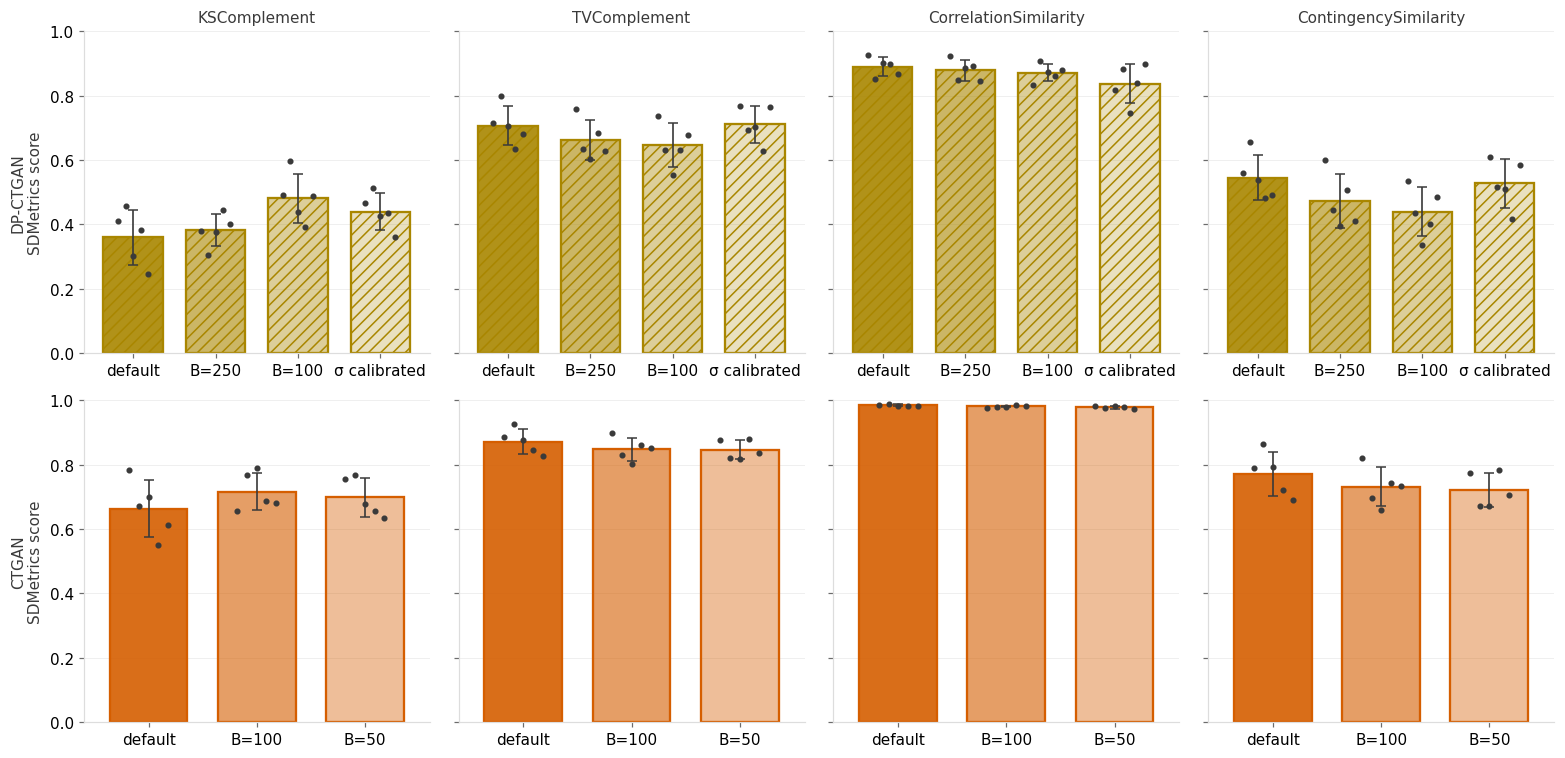

In [3]:
fig, axes = plt.subplots(2, len(FIDELITY), figsize=(3.6 * len(FIDELITY), 7), sharey=True)
for r, method in enumerate(["dpctgan", "ctgan"]):
    for c, metric in enumerate(FIDELITY):
        ax = axes[r][c]
        seed_bars(ax, "fidelity", method, metric)
        ax.set_ylim(0, 1)
        if r == 0:
            ax.set_title(metric, fontsize=10, color=INK)
        if c == 0:
            ax.set_ylabel(f"{NAME[method]}\nSDMetrics score", color=INK)
fig.tight_layout()
fig.savefig(FIG / "hyperparameter_sensitivity_fidelity.png", bbox_inches="tight")
plt.show()

## 2. Utility

Train-synthetic-test-real AUC on the held-out test set, and retention = TSTR / TRTR (XGBoost).

The figure under the table shows TSTR AUC for each classifier, laid out like the fidelity figure. The dashed line is
TRTR: the same classifier trained on the real training data, i.e. the ceiling a synthetic training set could reach.

In [4]:
UTILITY = ["tstr_xgboost_auc", "tstr_logistic_regression_auc", "retention_xgboost"]
compare("utility", UTILITY)

tstr_xgboost_auc                   \
                              mean ± sd Δ vs default (p)   
generator arm                                              
DP-CTGAN  default         0.649 ± 0.127                —   
          B=250           0.555 ± 0.163    -0.094 (0.34)   
          B=100           0.649 ± 0.057    -0.000 (1.00)   
          σ calibrated    0.662 ± 0.049    +0.013 (0.84)   
CTGAN     default         0.863 ± 0.005                —   
          B=100           0.859 ± 0.007    -0.004 (0.32)   
          B=50            0.845 ± 0.011    -0.017 (0.02)   

                       tstr_logistic_regression_auc                   \
                                          mean ± sd Δ vs default (p)   
generator arm                                                          
DP-CTGAN  default                     0.601 ± 0.073                —   
          B=250                       0.568 ± 0.053    -0.033 (0.44)   
          B=100                       0.589 ± 0.114    -0.012 (0.85)   
          σ calibrated                0.629 ± 0.113    +0.028 (0.65)   
CTGAN     default                     0.871 ± 0.004                —   
          B=100                       0.866 ± 0.005    -0.005 (0.13)   
          B=50                        0.861 ± 0.005    -0.011 (0.01)   

                       retention_xgboost                   
                               mean ± sd Δ vs default (p)  
generator arm                                              
DP-CTGAN  default          0.700 ± 0.137                —  
          B=250            0.598 ± 0.175    -0.102 (0.34)  
          B=100            0.700 ± 0.061    -0.000 (1.00)  
          σ calibrated     0.714 ± 0.053    +0.014 (0.84)  
CTGAN     default          0.930 ± 0.006                —  
          B=100            0.926 ± 0.007    -0.004 (0.32)  
          B=50             0.911 ± 0.012    -0.019 (0.02)

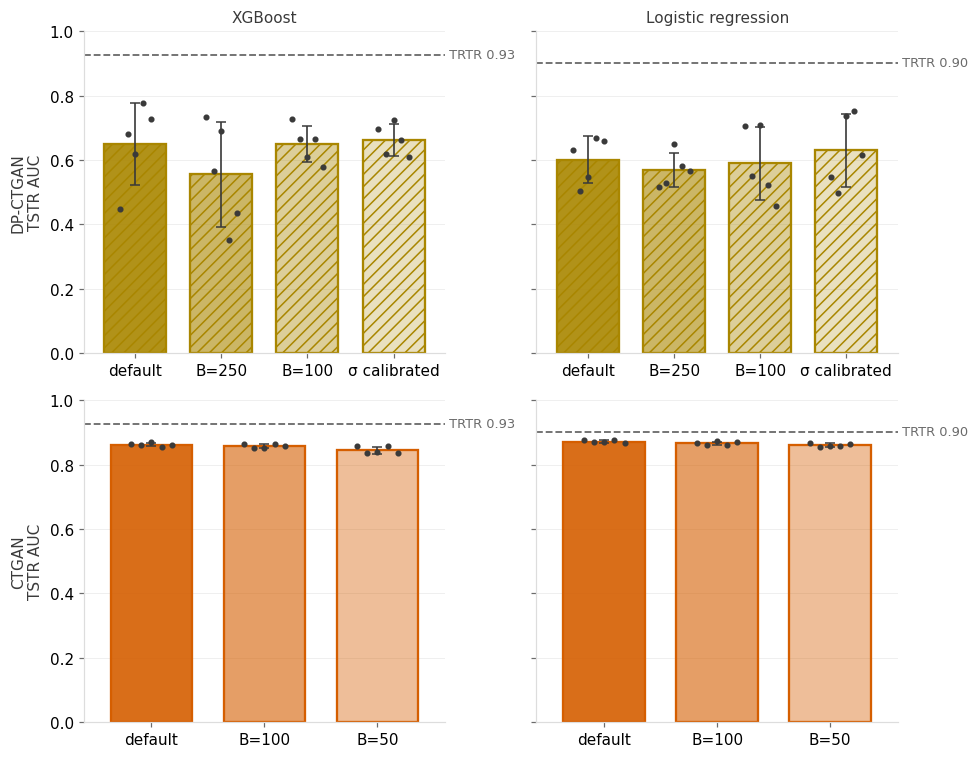

In [5]:
CLASSIFIERS = [("tstr_xgboost_auc", "trtr_xgboost_auc", "XGBoost"),
               ("tstr_logistic_regression_auc", "trtr_logistic_regression_auc", "Logistic regression")]
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharey=True)
for r, method in enumerate(["dpctgan", "ctgan"]):
    for c, (tstr, trtr, name) in enumerate(CLASSIFIERS):
        ax = axes[r][c]
        seed_bars(ax, "utility", method, tstr)
        ref = per_run("utility", method, None)[trtr].mean()
        ax.axhline(ref, color=MUTED, ls="--", lw=1.2, zorder=1)
        ax.text(ax.get_xlim()[1], ref, f" TRTR {ref:.2f}", fontsize=8.5, color=MUTED, va="center", ha="left")
        ax.set_ylim(0, 1)
        if r == 0:
            ax.set_title(name, fontsize=10, color=INK)
        if c == 0:
            ax.set_ylabel(f"{NAME[method]}\nTSTR AUC", color=INK)
fig.tight_layout()
fig.savefig(FIG / "hyperparameter_sensitivity_utility.png", bbox_inches="tight")
plt.show()

## 3. Privacy

The 1000/2500 TAPAS audit (500-row training set, 5 attacks). Per arm:

- **max AUC**: the strongest attack. The 95% null band at 1250 + 1250 test datasets is 0.5 ± 0.023; inside it, the
  attack cannot be told apart from guessing.
- **attacks above null**: how many of the 5 attacks have AUC above that band.
- **eff-ε (worst attack)**: the largest 95% lower bound on effective ε across the attacks, with its interval.
  0 means no attack shows leakage at 95% confidence.
- **MIA advantage**: TPR − FPR, mean ± sd over the 5 attacks (the y-axis of the tradeoff plot below).

The figure under the table is the MIA AUC chart from `privacy_analysis.ipynb` (section 4), with one panel per generator and
one bar per variant. The shaded band is the 95% interval under H0 (member and non-member scores indistinguishable), the
dashed line is AUC = 0.5, and a dot above a bar marks an AUC outside the band.

In [6]:
def null_halfwidth(n1, n2):
    return 1.96 * np.sqrt((n1 + n2 + 1) / (12 * n1 * n2))   # as in privacy_analysis.ipynb

NULL_HW = null_halfwidth(1250, 1250)

def audit(method, audit_dir):
    path = audit_dir / "1000_2500" / f"effeps_{method}_1000_2500.csv"
    return pd.read_csv(path) if path.exists() else None

rows = []
for method, label, tag, audit_dir in ARMS:
    a = audit(method, audit_dir)
    row = {"generator": NAME[method], "arm": label}
    if a is None:
        row.update({"max AUC (attack)": "pending", "attacks above null": "", "eff-ε (worst attack)": "",
                    "MIA advantage": ""})
    else:
        a = a.assign(attack=a.attack.str.split("(").str[0])
        top = a.loc[a.auc.idxmax()]
        worst = a.loc[a.eps_low_95.idxmax()]
        row.update({
            "max AUC (attack)": f"{top.auc:.3f} ({top.attack})",
            "attacks above null": int((a.auc > 0.5 + NULL_HW).sum()),
            "eff-ε (worst attack)": (f"{worst.eps_low_95:.3f} [{worst.eps_low_95:.3f}, {worst.eps_high_95:.3f}] "
                                     f"({worst.attack})" if worst.eps_low_95 > 0 else "0 (all attacks)"),
            "MIA advantage": f"{a.mia_advantage.mean():.3f} ± {a.mia_advantage.std(ddof=1):.3f}",
        })
    rows.append(row)
print(f"null band: AUC 0.5 ± {NULL_HW:.3f}")
pd.DataFrame(rows).set_index(["generator", "arm"])

null band: AUC 0.5 ± 0.023


max AUC (attack)  attacks above null  \
generator arm                                                               
DP-CTGAN  default             0.513 (ShadowModelling)                   0   
          B=250               0.512 (ClosestDistance)                   0   
          B=100         0.509 (ProbabilityEstimation)                   0   
          σ calibrated  0.520 (ProbabilityEstimation)                   0   
CTGAN     default                   0.701 (Groundhog)                   2   
          B=100                     0.572 (Groundhog)                   1   
          B=50                      0.568 (Groundhog)                   3   

                                    eff-ε (worst attack)   MIA advantage  
generator arm                                                             
DP-CTGAN  default                        0 (all attacks)   0.004 ± 0.010  
          B=250                          0 (all attacks)   0.003 ± 0.013  
          B=100                          0 (all attacks)   0.006 ± 0.009  
          σ calibrated                   0 (all attacks)  -0.000 ± 0.017  
CTGAN     default       0.801 [0.801, 1.572] (Groundhog)   0.056 ± 0.139  
          B=100                          0 (all attacks)   0.020 ± 0.042  
          B=50                           0 (all attacks)   0.045 ± 0.035

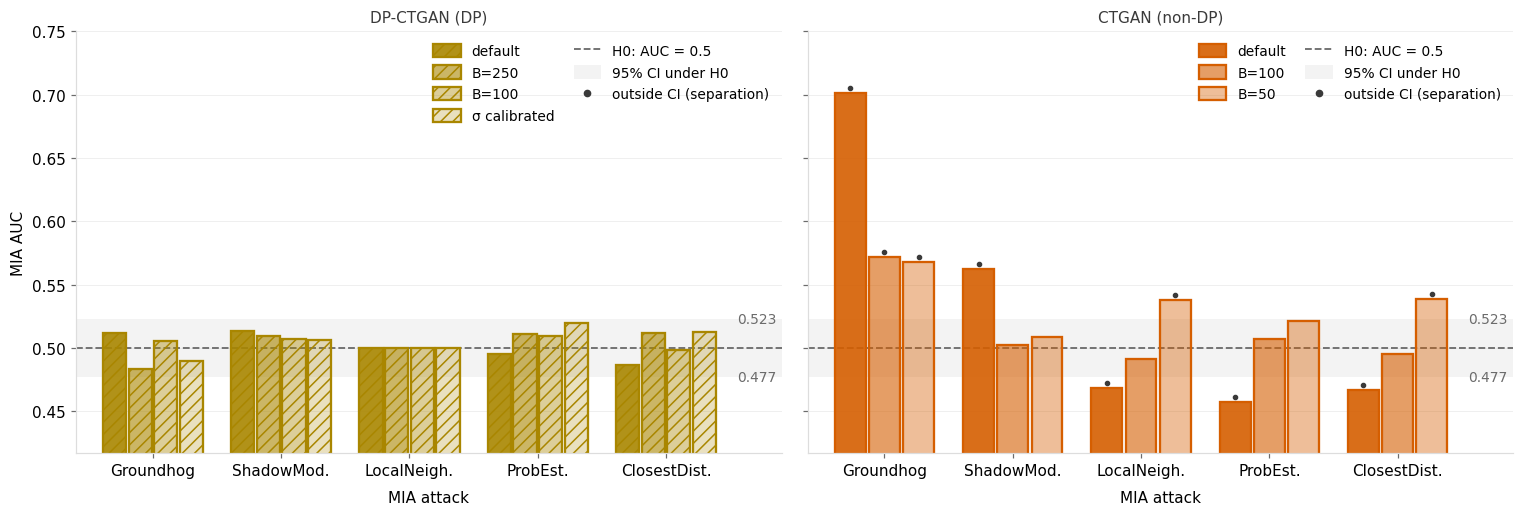

In [7]:
ATTACKS = ["Groundhog", "ShadowModelling", "LocalNeighbourhood", "ProbabilityEstimation", "ClosestDistance"]
SHORT_ATK = {"Groundhog": "Groundhog", "ShadowModelling": "ShadowMod.", "LocalNeighbourhood": "LocalNeigh.",
             "ProbabilityEstimation": "ProbEst.", "ClosestDistance": "ClosestDist."}

auc = {}                                   # (method, label) -> AUC per attack, in ATTACKS order
for method, label, tag, audit_dir in ARMS:
    a = audit(method, audit_dir)
    a = a.assign(attack=a.attack.str.split("(").str[0]).set_index("attack")
    auc[(method, label)] = a.loc[ATTACKS, "auc"].values
YLO, YHI = min(v.min() for v in auc.values()) - .04, .75

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, method in zip(axes, ["dpctgan", "ctgan"]):
    vs = variants(method)
    x = np.arange(len(ATTACKS)); width = .8 / len(vs)
    offs = np.arange(len(vs)) - (len(vs) - 1) / 2
    ax.axhspan(.5 - NULL_HW, .5 + NULL_HW, facecolor=GRID, edgecolor="none", alpha=.35, zorder=0)
    ax.axhline(.5, color=MUTED, ls="--", lw=1.2, zorder=1)
    for sign in (-1, 1):
        ax.text(x[-1] + .55, .5 + sign * NULL_HW, f"{.5 + sign * NULL_HW:.3f}", fontsize=9, color=MUTED,
                va="center", ha="left")
    swatches = []
    for i, (label, tag) in enumerate(vs):
        vals = auc[(method, label)]
        bars = ax.bar(x + offs[i] * width, vals, width * .9, zorder=2, **bar_style(method, i))
        for p in bars:                        # clip each outline to its own bar so the stroke does not lift it
            p.set_clip_path(p); p.set_clip_box(ax.bbox)
        out = np.abs(vals - .5) > NULL_HW
        ax.scatter((x + offs[i] * width)[out], vals[out] + .012 * (YHI - YLO), s=7, color=INK, zorder=4)
        swatches.append(plt.Rectangle((0, 0), 1, 1, **bar_style(method, i)))
    ax.set_xticks(x); ax.set_xticklabels([SHORT_ATK[a] for a in ATTACKS], fontsize=10, color="black")
    ax.set_xlim(x[0] - .6, x[-1] + .9); ax.set_ylim(YLO, YHI)
    ax.set_title(f"{NAME[method]} ({'DP' if GEN_DP[method] else 'non-DP'})", fontsize=10, color=INK)
    ax.set_xlabel("MIA attack", color="black", labelpad=8)
    tidy(ax); ax.tick_params(labelcolor="black"); ax.grid(axis="y", color=GRID, lw=.6, alpha=.5)
    refs = [Line2D([], [], color=MUTED, ls="--", lw=1.2),
            plt.Rectangle((0, 0), 1, 1, facecolor=GRID, edgecolor="none", alpha=.35),
            Line2D([], [], marker="o", ls="", color=INK, markersize=4)]
    pad = [Line2D([], [], color="none")] * max(len(vs) - len(refs), 0)
    ax.legend(handles=swatches + refs + pad,
              labels=[l for l, _ in vs] + ["H0: AUC = 0.5", "95% CI under H0", "outside CI (separation)"]
                     + [""] * len(pad),
              loc="upper right", ncol=2, frameon=False, fontsize=9, handlelength=2.0, handleheight=1.1,
              columnspacing=1.4, labelspacing=.55, borderaxespad=.5)
axes[0].set_ylabel("MIA AUC", color="black")
fig.tight_layout()
fig.savefig(FIG / "hyperparameter_sensitivity_privacy_auc.png", bbox_inches="tight")
plt.show()

## 4. Privacy-utility tradeoff, default vs tuned

Same axes as the paper's tradeoff plot (`privacy_analysis.ipynb`, section 5): x is XGBoost AUC retention
(mean ± sd over 5 generation seeds), y is MIA advantage (mean ± sd over the 5 attacks). Both generators are neural, so
CTGAN is vermillion and DP-CTGAN is gold throughout. The default is a circle with a black border; every tuned variant is a
square, named by its label.

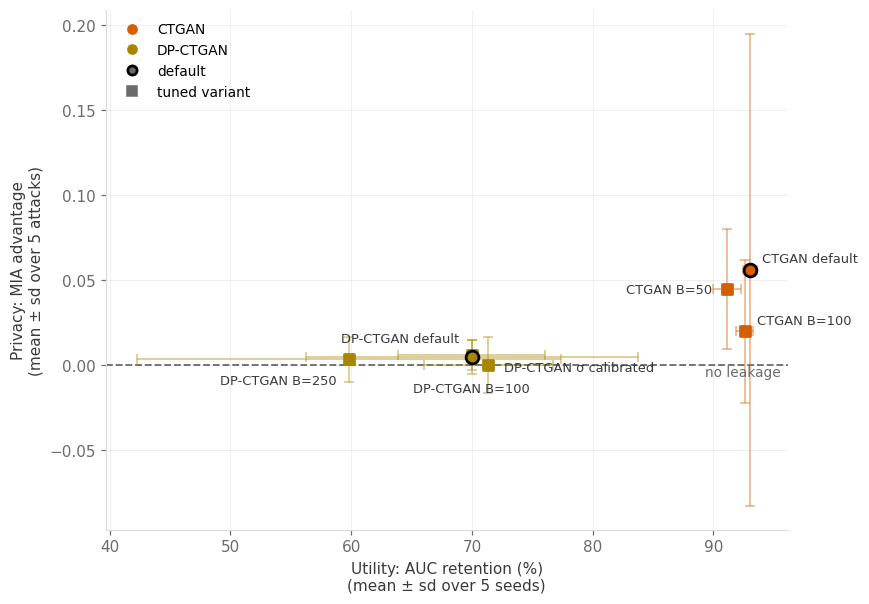

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.axhline(0, color=MUTED, ls="--", lw=1.2)
ax.text(0.99, 0.0, "no leakage", transform=ax.get_yaxis_transform(), fontsize=9, color=MUTED,
        va="top", ha="right")
# Hand-placed labels: three DP-CTGAN arms share x = 70.0 (identical retention), so one offset for all would stack them.
OFFSET = {("dpctgan", "default"): (-8, 10),
          ("dpctgan", "B=100"): (0, -24), ("dpctgan", "σ calibrated"): (10, -4),
          ("dpctgan", "B=250"): (-8, -16), ("ctgan", "B=50"): (-10, -3)}
for method, label, tag, audit_dir in ARMS:
    a = audit(method, audit_dir)
    if a is None:
        continue
    u = per_run("utility", method, tag)
    x, xs = 100 * u.retention_xgboost.mean(), 100 * u.retention_xgboost.std(ddof=1)
    y, ys = a.mia_advantage.mean(), a.mia_advantage.std(ddof=1)
    col = GEN_COLOR[method]
    ax.errorbar(x, y, xerr=xs, yerr=ys, fmt="none", ecolor=col, elinewidth=1, capsize=3, alpha=.5)
    ax.scatter(x, y, s=70 if label == "default" else 50, marker="o" if label == "default" else "s",
               facecolor=col, edgecolor="black" if label == "default" else col, lw=1.8,
               zorder=5 if label == "default" else 3)    # defaults on top: DP-CTGAN's sits almost under its B=100 variant
    dx, dy = OFFSET.get((method, label), (8, 5))
    ax.annotate(f"{NAME[method]} {label}", (x, y), textcoords="offset points", xytext=(dx, dy),
                fontsize=8.5, color=INK, ha="center" if dx == 0 else "left" if dx > 0 else "right")
tidy(ax)
ax.grid(color=GRID, lw=.6, alpha=.5)
ax.set_xlabel("Utility: AUC retention (%)\n(mean ± sd over 5 seeds)", color=INK)
ax.set_ylabel("Privacy: MIA advantage\n(mean ± sd over 5 attacks)", color=INK)
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=GEN_COLOR["ctgan"], mec=GEN_COLOR["ctgan"], label="CTGAN"),
                   Line2D([], [], marker="o", ls="", mfc=GEN_COLOR["dpctgan"], mec=GEN_COLOR["dpctgan"], label="DP-CTGAN"),
                   Line2D([], [], marker="o", ls="", mfc=MUTED, mec="black", mew=1.8, label="default"),
                   Line2D([], [], marker="s", ls="", mfc=MUTED, mec=MUTED, label="tuned variant")],
          loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "hyperparameter_sensitivity_tradeoff.png", bbox_inches="tight")
plt.show()

## Takeaways

Does moving one hyperparameter change the evaluation? Tuned arms against the default, 5 seeds for fidelity and utility,
1000/2500 audit for privacy. Across the 35 fidelity and utility tests, one or two p ≈ 0.05 results are expected by chance.

**Fidelity**
- **DP-CTGAN:** no consistent change. Only B=100 is borderline: KSComplement +0.12 (p = 0.046) and ContingencySimilarity
  −0.11 (p = 0.052), in opposite directions.
- **CTGAN:** essentially none. The one significant difference is CorrelationSimilarity at B=50, −0.006 (p = 0.04), a
  negligible size.

**Utility**
- **DP-CTGAN:** no change in any arm (all p ≥ 0.34).
- **CTGAN:** no change at B=100. B=50 is slightly lower: XGBoost TSTR −0.017 (p = 0.02), logistic regression −0.011
  (p = 0.01), XGBoost retention 0.930 → 0.911.

**Privacy**
- **DP-CTGAN:** no arm shows leakage. The strongest attack's AUC is at most 0.52 (inside the null band, 0.5 ± 0.023) and
  the eff-ε lower bound is 0 for every attack, including the σ-calibrated arm that trains all 300 epochs.
- **CTGAN:** smaller batches sharply reduce the strongest leak. At the default (B=200, re-audited on gpu4-0) Groundhog
  reaches AUC 0.701 with an eff-ε 95% lower bound of 0.801 [0.801, 1.572]. At B=100 and B=50 Groundhog falls to AUC 0.572
  and 0.568, and no attack's eff-ε lower bound clears 0. Groundhog is weaker, not gone: it still sits above the null band
  at both. The other four attacks stay within 0.06 of chance in every arm. At B=100 all five move closer to 0.5; at B=50
  two of them (LocalNeighbourhood, ClosestDistance) end about as far from 0.5 as at the default, on the other side, so
  the mean MIA advantage barely moves (0.056 → 0.045). Those shifts are small next to Groundhog's drop.
- **Not the server:** the gpu4-0 re-audits reproduce the original gpu2-119-3 audits (CTGAN Groundhog 0.717, lower bound
  0.846; DP-CTGAN null in both).

**Bottom line**
- **DP-CTGAN:** tuning does not change the evaluation.
- **CTGAN:** fidelity and utility hold up (a small utility cost at B=50), but how much leakage the audit measures depends
  on the batch size.

**Caveats:** the default fidelity and utility rows are the original gpu2-119-3 runs (only privacy was re-run on gpu4-0);
two batch sizes per generator and one σ-calibrated arm is a thin grid; one knob moved at a time, so interactions are
untested; the audit uses one target and background.